In [77]:
import os
from PIL import Image
import pandas as pd
import seaborn as seaborn
from PIL import Image
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt


## Vérification nombre d'images de chaque tumeur Training

Ce code permet d'afficher les types de tumeur différentes et le nombre d'images associés à chacune des tumeurs.

In [78]:
liste_tumeur = {}                                                   # On initialise un dictionnaire vide pour stocker chaque tumeurs et le nombre d'images associées

dossier = os.listdir("Dataset/Training")                            # C'est le dossier que l'on va parcourir pour trouver les différentes tumeurs

for k in dossier:                                                   # La boucle qui permet de parcours le dossier pour trouver les différents dossiers relatifs à chaque tumeur
    if k not in liste_tumeur:
        liste_tumeur[k] = 0                                         # On ajoute à la boucle que si elle n'est pas déjà présente dans le dictionnaire

print (f"Liste des différentes tumeurs : {liste_tumeur}") 

for j in liste_tumeur:                                              # On parcourt tout le dictionnaire qui vient d'être rempli 
    dossier_actuel = os.path.join("Dataset/Training", j)            # Les dossiers à parcourir sont donc les différents dossier de tumeurs
    for l in os.listdir(dossier_actuel):
        liste_tumeur[j] += 1                                        # On ajoute 1 à chaque image de chaque tumeurs

print (f"Nombre d'images de chaque tumeur : {liste_tumeur}") 

Liste des différentes tumeurs : {'notumor': 0, 'meningioma': 0, 'pituitary': 0, 'glioma': 0}
Nombre d'images de chaque tumeur : {'notumor': 1400, 'meningioma': 1400, 'pituitary': 1400, 'glioma': 1400}


## Graphique nombre d'image de chaque tumeur Training

<Axes: xlabel='Type_Tumeur', ylabel='Count'>

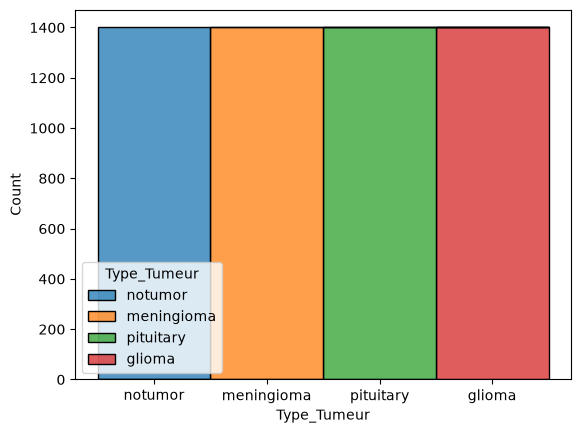

In [79]:
df = pd.DataFrame(list(liste_tumeur.items()), columns=['Type_Tumeur', 'Valeur'])                        # Pour faire un graphique, on transforme le dictionnaire en Dataframe
seaborn.histplot(data=df, x='Type_Tumeur', weights='Valeur', hue='Type_Tumeur', multiple='stack')       # Création du graphique

## Début préprocess (Récupération des infos des images)

In [80]:
df.head()                                                                   # class de df
df.info()                                                                   # infos du nombre d'entrée du df
df.describe()                                                               # Description df (nombre colonne / infos à l'interieur ...)

liste_taille = {}                                                           # On initialise 3 nouveeux dictionnaires pour les 3 vérifications
liste_format = {}
liste_couleur = {}

for j in liste_tumeur.keys():                                               # On va parcourir les différents dossier de tumeurs et regarder les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        img = Image.open(fichier_actuel)
        if img.size not in liste_taille.keys():                             # Ajout des différentes dimensions des images
            liste_taille[img.size] = 1
        else:
            liste_taille[img.size] += 1
        if img.format not in liste_format.keys():                           # Ajout de différent format de compression d'image (PNG, JPEG ...)
            liste_format[img.format] = 1
        else:
            liste_format[img.format] += 1 
        if img.mode not in liste_couleur:                                   # Ajout des différent mode de colorimétrie des images (J, RGB, RGBA ...)
            liste_couleur[img.mode] = 1
        else:
            liste_couleur[img.mode] += 1

taille_max = max(liste_taille, key=liste_taille.get)                        # Dimensions les plus présentes
format_max = max(liste_format, key=liste_format.get)                        # Format le plus présent
couleur_max = max(liste_couleur, key=liste_couleur.get)                     # Couleur la plus présente
print ("Type de dimensions : ", liste_taille)
print ("Type de formats : ", liste_format)
print ("Type de couleurs : ", liste_couleur)
print("Dimensions les plus présentes :", str(taille_max) + ". Nombre d'images avec ces dimensions :", liste_taille[taille_max])
print("Format le plus présent :", format_max + ". Nombre d'images avec ce format :", liste_format[format_max])
print("Couleur la plus présente :", couleur_max + ". Nombre d'images avec ce mode de colorimétrie :", liste_couleur[couleur_max])

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Type_Tumeur  4 non-null      str  
 1   Valeur       4 non-null      int64
dtypes: int64(1), str(1)
memory usage: 196.0 bytes
Type de dimensions :  {(235, 215): 1, (680, 680): 12, (225, 225): 253, (236, 300): 2, (228, 221): 32, (1024, 1024): 5, (194, 259): 8, (550, 664): 15, (350, 393): 6, (215, 234): 19, (150, 198): 33, (630, 630): 69, (236, 213): 17, (214, 236): 19, (512, 512): 4012, (206, 244): 26, (235, 214): 10, (350, 350): 11, (173, 201): 26, (177, 197): 6, (236, 240): 1, (207, 243): 11, (926, 649): 2, (359, 449): 16, (218, 231): 22, (442, 454): 13, (212, 238): 8, (236, 262): 2, (236, 236): 39, (204, 247): 1, (236, 357): 5, (201, 251): 40, (232, 217): 32, (300, 168): 8, (605, 613): 2, (196, 257): 11, (339, 340): 12, (205, 249): 2, (441, 442): 13, (230, 282): 15, (208, 248): 4, (442, 442): 38, (450, 504): 1, (

## Première conclusion

Tout d'abord, à la base, on à bien vérifier qu'il y a bien le <b>même nombre d'images</b> pour CHAQUE tumeur, et pour les images SANS tumeurs.

On peut le remarquer via les <b>première vérification</b> ainsi que le <u>graphique</u>. Nous avons en tout, <u>5600 images</u>, réparties en <b>4 catégories</b>, ce qui fait 1400 images par catégorie.

Ensuite, nous avons vérifier les <u>différents éléments</u> de chaques images. Comme leurs <b>dimensions</b>, leurs <b>formats</b> et leurs <b>colorimétries.</b>

On a pu voir que sur les <u>5600 images</u>, 4012 était en (512, 512) ce qui va très certainement devenir nos dimensions par défaut. <b>Cependant</b> il faudra faire attention, car certaines images ne sont pas des carrés. Signifiant qu'une conversion sans vérification pourrait applatir ou couper l'image. 

Ensuite, il y en a 5596 en <b>JPEG</b> et 4 en format <b>PNG</b>, bien que noté comme JPEG. Malgré que ces deux formats de compressions soient différents, nous ne trouvons pas cela dérangeant et <u>décidons de ne pas toucher à ces quatres images</u>. Les enlever serai complément contre-productif étant donné qu'elles reste exploitables comme les autres, et peuvent être comparées entre-elles sans difficultés.

Et enfin, leurs colorimétrie. Le plus courant est le <b>RGB</b> avec 3238 images, cependant, malgré qu'elle soit noté comme en <b>RGB</b>, un IRM n'utilise que des nuances de gris, signifiant que la transformation de toutes les images en mode <b>L (Lab / ou CIELLaB)</b> c'est à dire avec des nuances de gris sur une échelle de 0 à 100. 

Pour notre première étape de normalisation, nous décidons donc : 

- <u>De passer toutes les images en noir et blanc.
- De passer toutes les images en dimensions (512, 512)
- De laisser les images avec leurs modes car 99.9% sont en JPEG</u>

## Premier Preprocess

In [81]:
X_train = []
y_train = []

for j in liste_tumeur.keys():                                                               # On va reparcourir toutes les images
    dossier_actuel = os.path.join("Dataset/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset/Training", j, l)
        Dossier_cible = os.path.join("Dataset_clean/Training", j)
        img = Image.open(fichier_actuel)
        if img.mode not in ("L", "l"):                                                      # Si l'image n'est pas en noir et blanc, alors on la convertit
            img = img.convert('L')

        if img.size != (512, 512):

            ratio = 512 / max(img.size)

            nouvelle_taille = (
                int(img.size[0] * ratio),
                int(img.size[1] * ratio)
            )

            img = img.resize(nouvelle_taille)

            nouvelle_img = Image.new("L", (512, 512))

            x = (512 - img.size[0]) // 2
            y = (512 - img.size[1]) // 2

            nouvelle_img.paste(img, (x, y))

            img = nouvelle_img

            os.makedirs(Dossier_cible, exist_ok=True)
            img.save(os.path.join(Dossier_cible, l))

        else:
            os.makedirs(Dossier_cible, exist_ok=True)
            img.save(os.path.join(Dossier_cible, l))
        img_array = np.asarray(img, dtype=np.float32) / 255.0

        # Transformation de (512, 512) en (262144,)
        img_array = img_array.flatten()

        X_train.append(img_array)
        y_train.append(j)
    
        

## Vérification formats images

In [82]:
for j in liste_tumeur.keys():                                               # Vérification que toutes les images sont dans les mêmes formats (dimensions, colorimétrie)
    dossier_actuel = os.path.join("Dataset_clean/Training", j)
    for l in os.listdir(dossier_actuel):
        fichier_actuel = os.path.join("Dataset_clean/Training", j, l)
        img = Image.open(fichier_actuel)
        print 
        if img.size != (512, 512):
            print("MAUVAISES DIMENSIONS DETECTÉES")

## Vérification des doublons.

In [83]:
# for j in liste_tumeur.keys():
#     dossier_actuel = os.path.join("Dataset/Training", j)
#     fichiers = os.listdir(dossier_actuel)

#     for i in range(len(fichiers)):
#         for k in range(i + 1, len(fichiers)):
#             image_actuelle = os.path.join(dossier_actuel, fichiers[i])
#             image_suivante = os.path.join(dossier_actuel, fichiers[k])

#             img1 = Image.open(image_actuelle)
#             img2 = Image.open(image_suivante)
#     print("yeah")

In [84]:
X = np.array(X_train)
y = np.array(y_train)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (5600, 262144)
Dimensions de y : (5600,)


In [85]:


X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train_knn.shape)
print("X_test :", X_test_knn.shape)

X_train : (4480, 262144)
X_test : (1120, 262144)


In [ ]:

meilleur = 0.0
meilleur_chiffre = 0
for k in range(1, 8, 2):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_knn)

    y_pred = knn.predict(X_test_knn)

    accuracy = accuracy_score(y_test_knn, y_pred)
    if accuracy > meilleur:
        meilleur = accuracy
        meilleur_chiffre = k
    print(meilleur, meilleur_chiffre)
print(f"Meilleur résultat du KNN via n_neighbors = {meilleur_chiffre} :", meilleur)

0.9116071428571428 1
0.9116071428571428 1
0.9116071428571428 1
0.9116071428571428 1
Meilleur résultat du KNN via n_neighbors = 7 : 0.9116071428571428


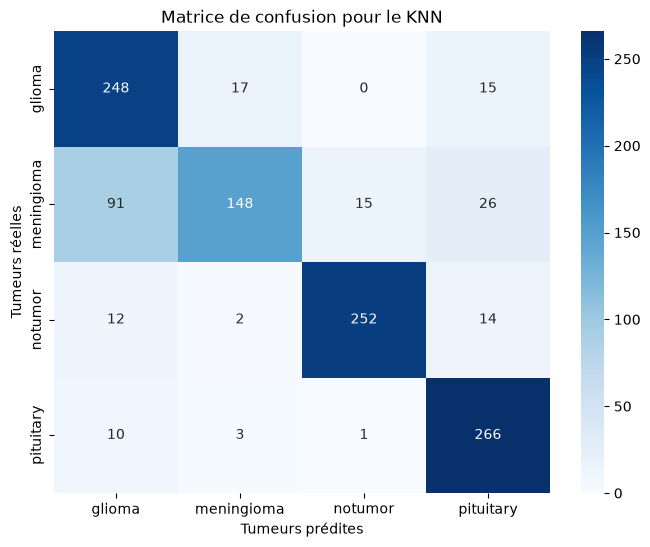

In [94]:

cm = confusion_matrix(y_test_knn, y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=knn.classes_, yticklabels=knn.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le KNN")

plt.show()

In [95]:
randomforest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
randomforest.fit(X_train_knn, y_train_knn)

y_pred = randomforest.predict(X_test_knn)

accuracy = accuracy_score(y_test_knn, y_pred)
print("Résultat du RandomForestClassifier :", accuracy)

Résultat du RandomForestClassifier : 0.9142857142857143


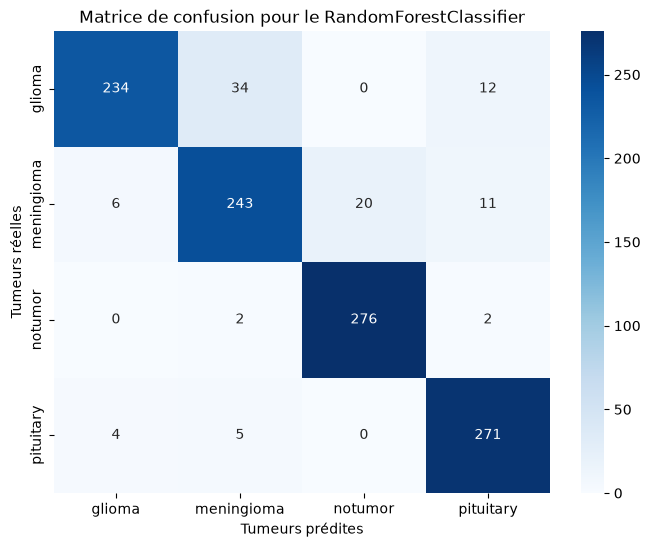

In [96]:
cm = confusion_matrix(y_test_knn, y_pred)

plt.figure(figsize=(8, 6))

seaborn.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=randomforest.classes_, yticklabels=randomforest.classes_)

plt.xlabel("Tumeurs prédites")
plt.ylabel("Tumeurs réelles")
plt.title("Matrice de confusion pour le RandomForestClassifier")

plt.show()